Dataset: https://www.kaggle.com/datasets/arjunbhasin2013/ccdata

# 1. Preparing Project <a id=1.1></a>

## 1.1 Importing Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

## 1.2 Importing Dataset

In [3]:
df = pd.read_csv("data/CC GENERAL.csv")

# 2. Analyzing DataFrame <a id=2></a>

In [4]:
df.shape

(8950, 18)

In [5]:
df.columns

Index(['CUST_ID', 'BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES',
       'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE',
       'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY',
       'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY',
       'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS',
       'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE'],
      dtype='str')

In [6]:
df.head()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [7]:
df.dtypes

CUST_ID                                 str
BALANCE                             float64
BALANCE_FREQUENCY                   float64
PURCHASES                           float64
ONEOFF_PURCHASES                    float64
INSTALLMENTS_PURCHASES              float64
CASH_ADVANCE                        float64
PURCHASES_FREQUENCY                 float64
ONEOFF_PURCHASES_FREQUENCY          float64
PURCHASES_INSTALLMENTS_FREQUENCY    float64
CASH_ADVANCE_FREQUENCY              float64
CASH_ADVANCE_TRX                      int64
PURCHASES_TRX                         int64
CREDIT_LIMIT                        float64
PAYMENTS                            float64
MINIMUM_PAYMENTS                    float64
PRC_FULL_PAYMENT                    float64
TENURE                                int64
dtype: object

In [10]:
df.isnull().sum()

CUST_ID                               0
BALANCE                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES_FREQUENCY            0
PURCHASES_INSTALLMENTS_FREQUENCY      0
CASH_ADVANCE_FREQUENCY                0
CASH_ADVANCE_TRX                      0
PURCHASES_TRX                         0
CREDIT_LIMIT                          1
PAYMENTS                              0
MINIMUM_PAYMENTS                    313
PRC_FULL_PAYMENT                      0
TENURE                                0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

## 2.1 Understanding Variables <a id=2.1></a>

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   str    
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHASES_TRX    

1. **CUST_ID**: Unique identifier for each customer.
2. **BALANCE**: The amount of money the customer currently owes on their credit card.
3. **BALANCE_FREQUENCY**: Frequency of balance updates.
4. **PURCHASES**: Total amount of purchases made by the customer.
5. **ONEOFF_PURCHASES**: Total amount of single, non-recurring purchases made by the customer.
6. **INSTALLMENTS_PURCHASES**: Total amount of purchases made in installments.
7. **CASH_ADVANCE**: Total amount of cash advances taken by the customer.
8. **PURCHASES_FREQUENCY**: Frequency of purchases made by the customer.
9. **ONEOFF_PURCHASES_FREQUENCY**: Frequency of one-off purchases made by the customer.
10. **PURCHASES_INSTALLMENTS_FREQUENCY**: Frequency of purchases made in installments.
11. **CASH_ADVANCE_FREQUENCY**: Frequency of cash advances taken by the customer.
12. **CASH_ADVANCE_TRX**: Number of cash advance transactions made by the customer.
13. **PURCHASES_TRX**: Number of purchase transactions made by the customer.
14. **CREDIT_LIMIT**: Credit limit assigned to the customer.
15. **PAYMENTS**: Total amount of payments made by the customer.
16. **MINIMUM_PAYMENTS**: Total minimum payments due for the customer.
17. **PRC_FULL_PAYMENT**: Percentage of months in which the customer paid the full balance.
18. **TENURE**: Number of months the customer has been with the bank.

## 2.2 Check Unique Values <a id=2.2></a>

In [13]:
pd.DataFrame(df.nunique())

,0
CUST_ID,8950
BALANCE,8871
BALANCE_FREQUENCY,43
PURCHASES,6203
ONEOFF_PURCHASES,4014
INSTALLMENTS_PURCHASES,4452
CASH_ADVANCE,4323
PURCHASES_FREQUENCY,47
ONEOFF_PURCHASES_FREQUENCY,47
PURCHASES_INSTALLMENTS_FREQUENCY,47


## 2.3 Statistical Analysis

In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.474828,2081.531879,0.000000,128.281915,873.385231,2054.140036,19043.13856
BALANCE_FREQUENCY,8950.0,0.877271,0.236904,0.000000,0.888889,1.000000,1.000000,1.00000
PURCHASES,8950.0,1003.204834,2136.634782,0.000000,39.635000,361.280000,1110.130000,49039.57000
ONEOFF_PURCHASES,8950.0,592.437371,1659.887917,0.000000,0.000000,38.000000,577.405000,40761.25000
INSTALLMENTS_PURCHASES,8950.0,411.067645,904.338115,0.000000,0.000000,89.000000,468.637500,22500.00000
CASH_ADVANCE,8950.0,978.871112,2097.163877,0.000000,0.000000,0.000000,1113.821139,47137.21176
PURCHASES_FREQUENCY,8950.0,0.490351,0.401371,0.000000,0.083333,0.500000,0.916667,1.00000
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.202458,0.298336,0.000000,0.000000,0.083333,0.300000,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.364437,0.397448,0.000000,0.000000,0.166667,0.750000,1.00000
CASH_ADVANCE_FREQUENCY,8950.0,0.135144,0.200121,0.000000,0.000000,0.000000,0.222222,1.50000


## 2.4 Check Dtypes <a id=2.5></a>

In [15]:
df.select_dtypes(include='object').columns

Index(['CUST_ID'], dtype='str')

In [16]:
df.select_dtypes(include='number').columns

Index(['BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES',
       'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY',
       'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY',
       'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX',
       'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT',
       'TENURE'],
      dtype='str')

# 3. Preprocessing <a id=3></a>

## 3.1 Dealing With Missing Values <a id=3.1></a>

In [19]:
df.isnull().sum()

CUST_ID                             0
BALANCE                             0
BALANCE_FREQUENCY                   0
PURCHASES                           0
ONEOFF_PURCHASES                    0
INSTALLMENTS_PURCHASES              0
CASH_ADVANCE                        0
PURCHASES_FREQUENCY                 0
ONEOFF_PURCHASES_FREQUENCY          0
PURCHASES_INSTALLMENTS_FREQUENCY    0
CASH_ADVANCE_FREQUENCY              0
CASH_ADVANCE_TRX                    0
PURCHASES_TRX                       0
CREDIT_LIMIT                        0
PAYMENTS                            0
MINIMUM_PAYMENTS                    0
PRC_FULL_PAYMENT                    0
TENURE                              0
dtype: int64

In [18]:
# Add mean value instead of null value
# 'CREDIT_LIMIT', 'MINIMUM_PAYMENTS'

df['CREDIT_LIMIT'] = df['CREDIT_LIMIT'].fillna(df['CREDIT_LIMIT'].mean())
df['MINIMUM_PAYMENTS'] = df['MINIMUM_PAYMENTS'].fillna(df['MINIMUM_PAYMENTS'].mean())

## 3.2 Encoding Categorical Variable <a id=3.2></a>

In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   str    
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHASES_TRX    

In [21]:
df['CUST_ID'].head()

0    C10001
1    C10002
2    C10003
3    C10004
4    C10005
Name: CUST_ID, dtype: str

_This columns does not provide insightful information as it is only unique identitfier of customers. So we can simply remove this variable from our dataframe_

In [22]:
df = df.drop('CUST_ID', axis=1)
df.head(2)

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,40.900749,0.818182,95.4,0.0,95.4,0.000000,0.166667,0.0,0.083333,0.00,0,2,1000.0,201.802084,139.509787,0.000000,12
1,3202.467416,0.909091,0.0,0.0,0.0,6442.945483,0.000000,0.0,0.000000,0.25,4,0,7000.0,4103.032597,1072.340217,0.222222,12


# 4. EDA <a id=4></a>

## 4.1 Distributions <a id=4.1></a>

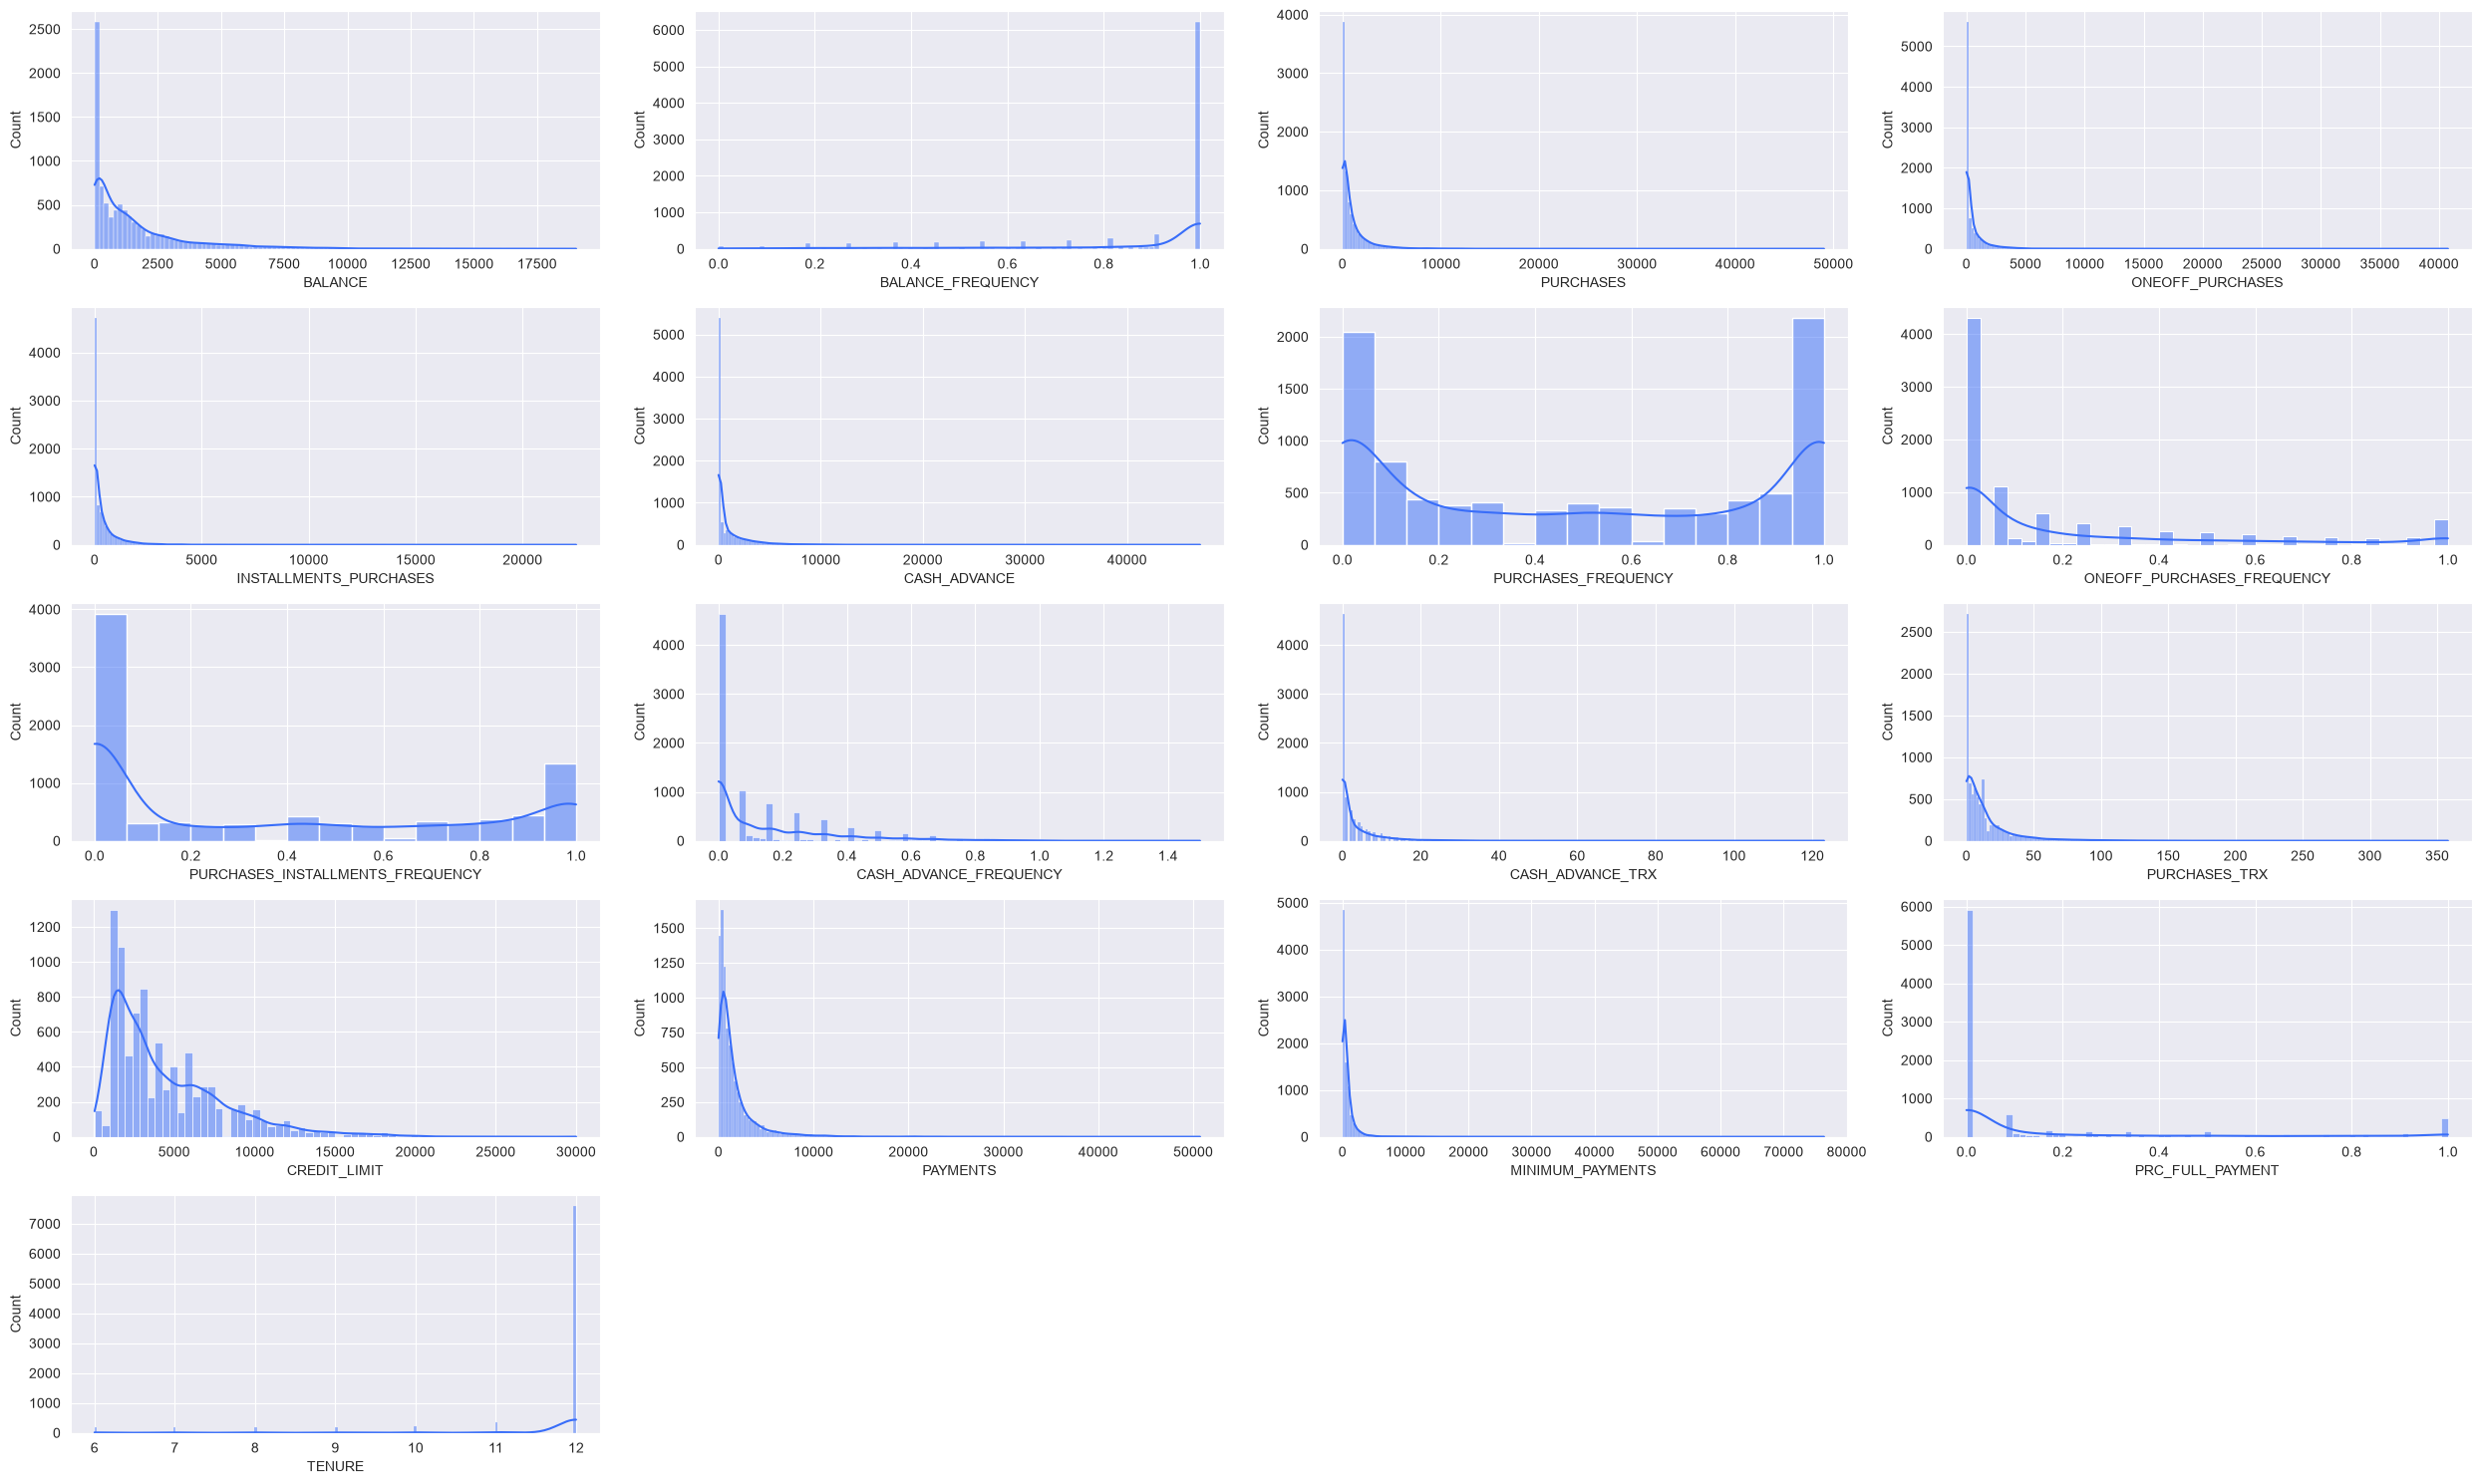

In [23]:
plt.figure(figsize=(25, 15))

for i, col in enumerate(df.columns, start=1):
    sns.set_style('darkgrid')
    sns.set_palette('rainbow')
    plt.subplot(5, 4, i)
    sns.histplot(data=df, x=col, bins='auto', kde=True)
plt.tight_layout()
plt.show()

## 4.2 Boxplot <a id=4.2></a>

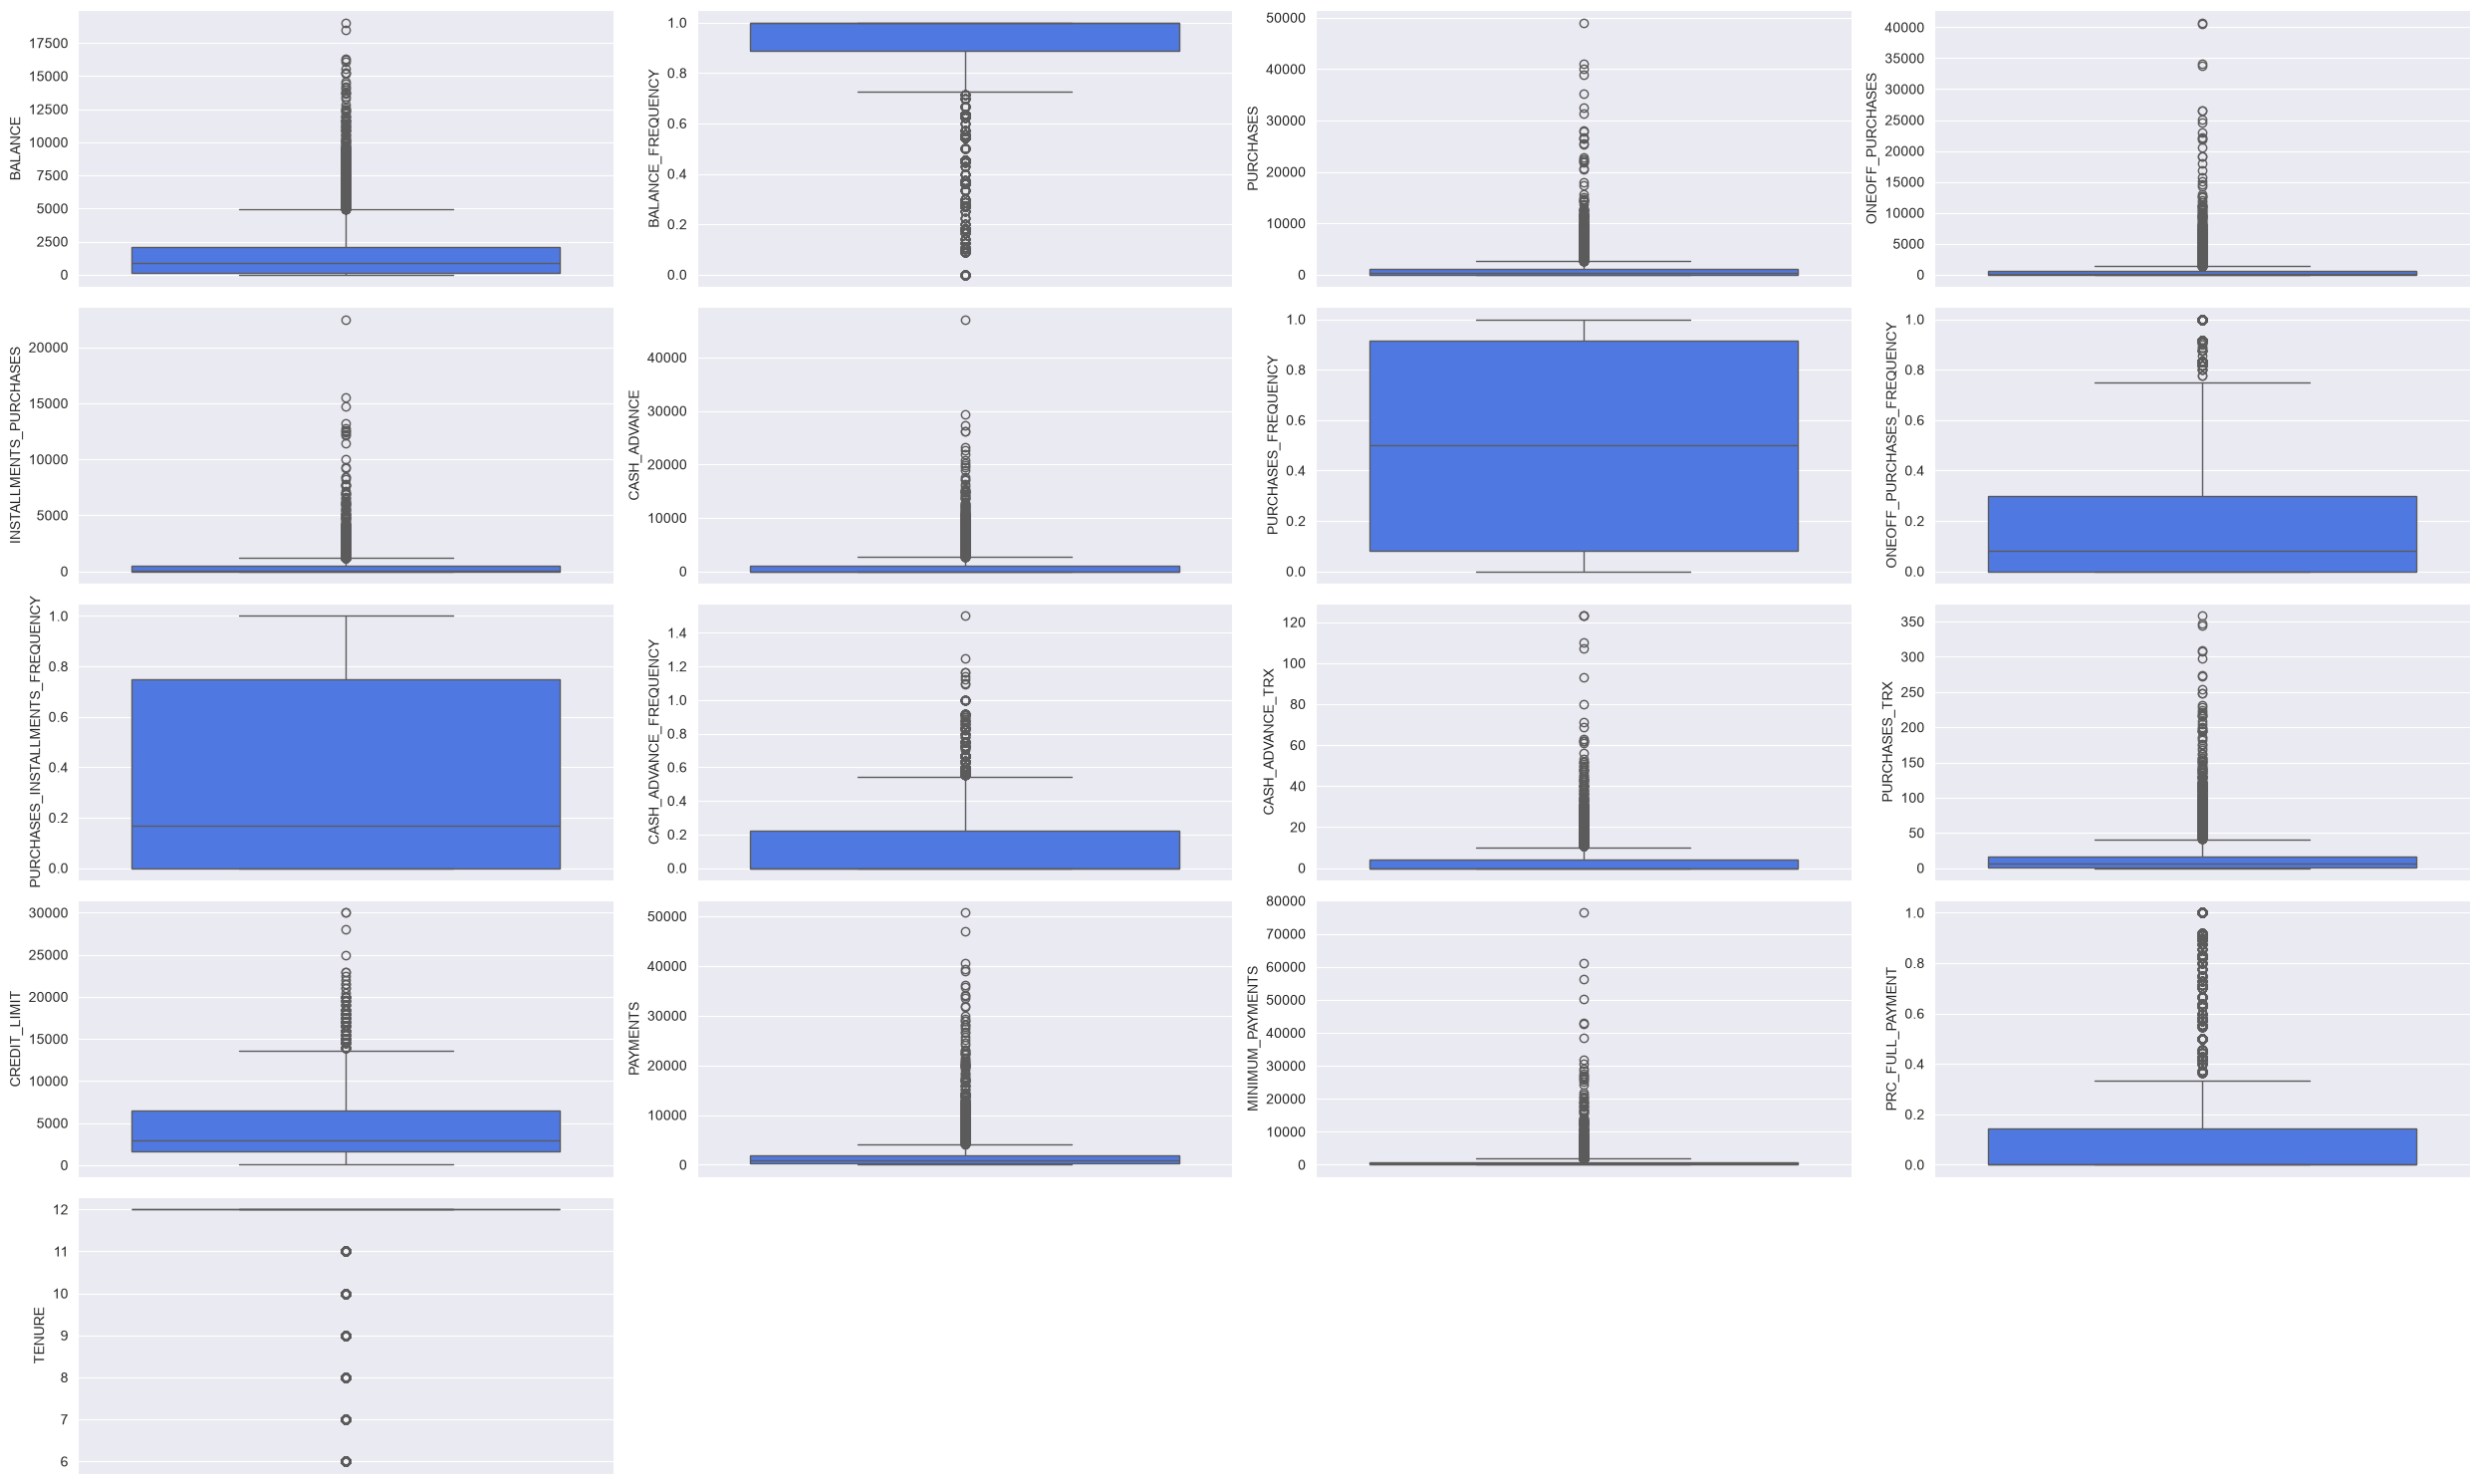

In [24]:
plt.figure(figsize=(25, 15))

for i, col in enumerate(df.columns, start=1):
    sns.set_style('darkgrid')
    sns.set_palette('rainbow')
    plt.subplot(5, 4, i)
    sns.boxplot(data=df, y=col)
plt.tight_layout()
plt.show()

## 4.3 Correlation <a id=4.3></a>

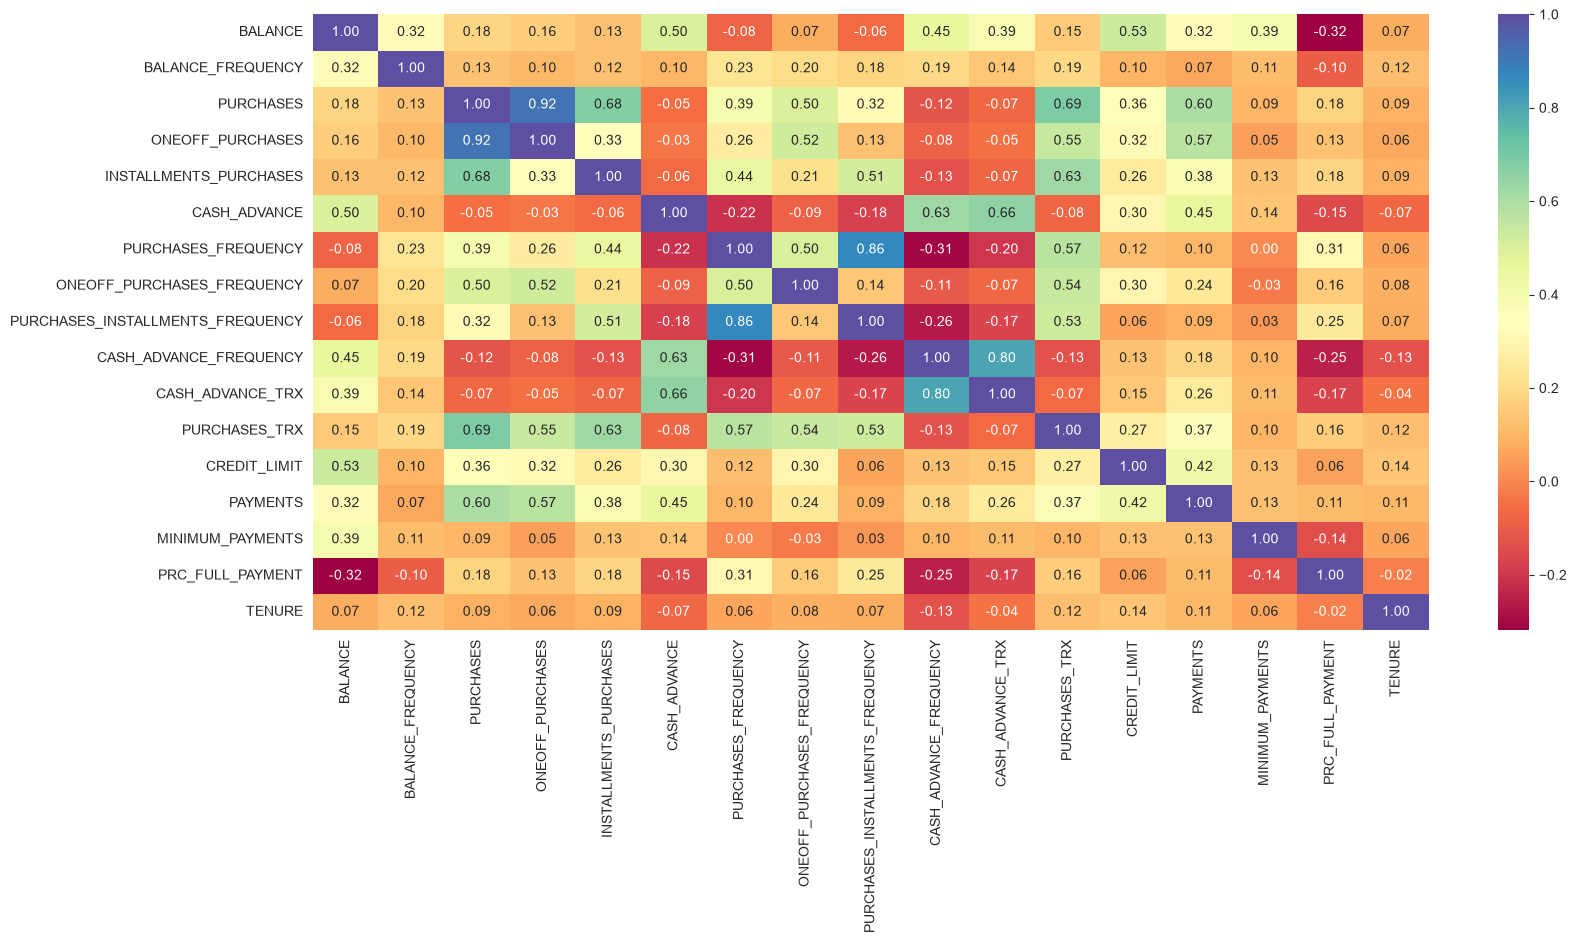

In [25]:
plt.figure(figsize=(18, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='Spectral')
plt.show()

# 5. Preparing For Modelling <a id=5></a>

## 5.1 Feature Scaling <a id=5.1></a>

In [26]:
df_2 = df.copy()
df_2.head(2)

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,40.900749,0.818182,95.4,0.0,95.4,0.000000,0.166667,0.0,0.083333,0.00,0,2,1000.0,201.802084,139.509787,0.000000,12
1,3202.467416,0.909091,0.0,0.0,0.0,6442.945483,0.000000,0.0,0.000000,0.25,4,0,7000.0,4103.032597,1072.340217,0.222222,12


In [27]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df_2 = scaler.fit_transform(df_2)
df_2

array([[-0.73198937, -0.24943448, -0.42489974, ..., -0.31096755,
        -0.52555097,  0.36067954],
       [ 0.78696085,  0.13432467, -0.46955188, ...,  0.08931021,
         0.2342269 ,  0.36067954],
       [ 0.44713513,  0.51808382, -0.10766823, ..., -0.10166318,
        -0.52555097,  0.36067954],
       ...,
       [-0.7403981 , -0.18547673, -0.40196519, ..., -0.33546549,
         0.32919999, -4.12276757],
       [-0.74517423, -0.18547673, -0.46955188, ..., -0.34690648,
         0.32919999, -4.12276757],
       [-0.57257511, -0.88903307,  0.04214581, ..., -0.33294642,
        -0.52555097, -4.12276757]], shape=(8950, 17))

In [28]:
df_2.shape

(8950, 17)

## 5.2 Finding Optimal Number Of Cluster <a id=5.2></a>

In [29]:
from sklearn.cluster import KMeans

wcss = []
for i in range(1, 20):
    k_means = KMeans(n_clusters=i, init='k-means++')
    k_means.fit(df_2)
    wcss.append(k_means.inertia_)

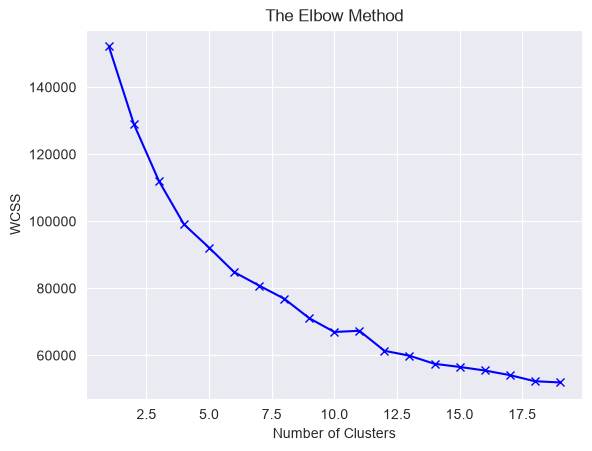

In [30]:
plt.plot(range(1, 20), wcss, 'bx-')
plt.title('The Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.show()

# 6. Modelling <a id=6></a>

## 6.1 Customer Clustering By KMeans <a id=6.1></a>

In [31]:
kmeans = KMeans(n_clusters=8, init='k-means++', random_state=42)

y_kmeans = kmeans.fit_predict(df_2)
# the values of y_kmeans will be in range from 0 to 7
# that is from cluster 1 to cluster 8
# the dependent variable will split all the customers into 8 different clusters

In [32]:
# Check y_kmeans
y_kmeans

array([7, 3, 5, ..., 2, 7, 1], shape=(8950,), dtype=int32)

### 6.1.1 Add Clusters to DataFrame <a id=6.1.1></a>

In [33]:
cluster_df = pd.DataFrame(y_kmeans, columns=['Cluster'])
cluster_df.head(2)

,Cluster
0,7
1,3


In [34]:
df_clst = pd.concat([df, cluster_df], axis=1)
df_clst

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE,Cluster
0,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12,7
1,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12,3
2,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12,5
3,1666.670542,0.636364,1499.00,1499.00,0.00,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,864.206542,0.000000,12,7
4,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8945,28.493517,1.000000,291.12,0.00,291.12,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,325.594462,48.886365,0.500000,6,2
8946,19.183215,1.000000,300.00,0.00,300.00,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,275.861322,864.206542,0.000000,6,2
8947,23.398673,0.833333,144.40,0.00,144.40,0.000000,0.833333,0.000000,0.666667,0.000000,0,5,1000.0,81.270775,82.418369,0.250000,6,2
8948,13.457564,0.833333,0.00,0.00,0.00,36.558778,0.000000,0.000000,0.000000,0.166667,2,0,500.0,52.549959,55.755628,0.250000,6,7


In [35]:
df_clst.groupby('Cluster')[df.columns].mean()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
Cluster,,,,,,,,,,,,,,,,,
0,5848.513259,0.967319,984.685104,562.119201,422.565903,8199.976109,0.423583,0.202623,0.319066,0.628334,25.187500,15.677083,9548.090278,7559.476647,2197.100405,0.069605,11.565972
1,113.079432,0.369563,329.738267,203.472183,126.496698,324.991337,0.265990,0.075709,0.181629,0.038477,0.749806,4.121212,3729.086165,1078.824664,269.364053,0.230989,11.280497
2,683.533299,0.949871,876.324406,184.679492,692.216408,187.504339,0.894130,0.089413,0.836427,0.038799,0.723180,18.132184,3287.318104,995.880147,567.450643,0.271281,11.460728
3,3506.772996,0.957363,277.925032,188.262592,89.743776,2976.582443,0.196866,0.094740,0.112327,0.424746,10.047200,4.008000,5940.643636,1983.310674,1237.215093,0.027541,11.136000
4,4425.362379,0.974886,16338.028250,11188.905375,5149.122875,1012.529590,0.924792,0.774489,0.774489,0.077083,2.512500,133.687500,12430.000000,16098.700812,2516.595215,0.406617,11.962500
5,1905.581748,0.979025,3012.417644,2065.636574,947.242964,354.805920,0.931512,0.753556,0.588272,0.056482,1.147806,44.481139,7108.350479,2867.930894,768.708281,0.280459,11.886836
6,4083.777061,0.987879,1008.174444,116.942444,891.232000,892.937661,0.516162,0.035859,0.486027,0.082997,2.622222,19.600000,4281.111111,1490.095282,25121.724754,0.000000,11.911111
7,1281.404990,0.965605,316.880413,257.933284,59.136521,492.432039,0.192899,0.118118,0.077001,0.108628,1.905473,3.676234,3048.456436,882.943813,648.105244,0.023234,11.652124


# END

# More Perfect Charts & Graphs

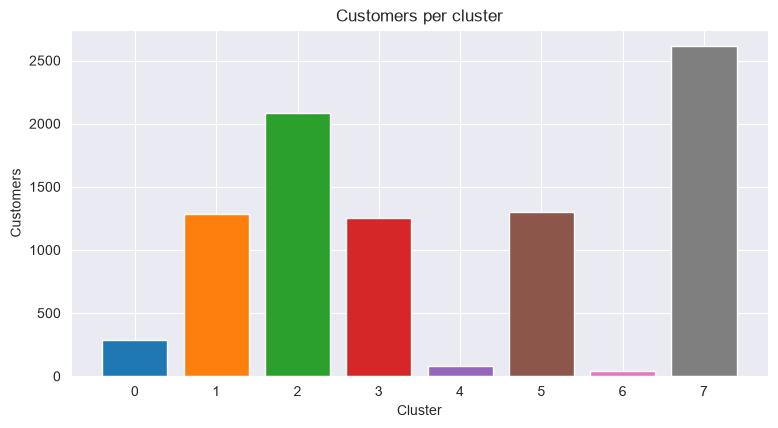

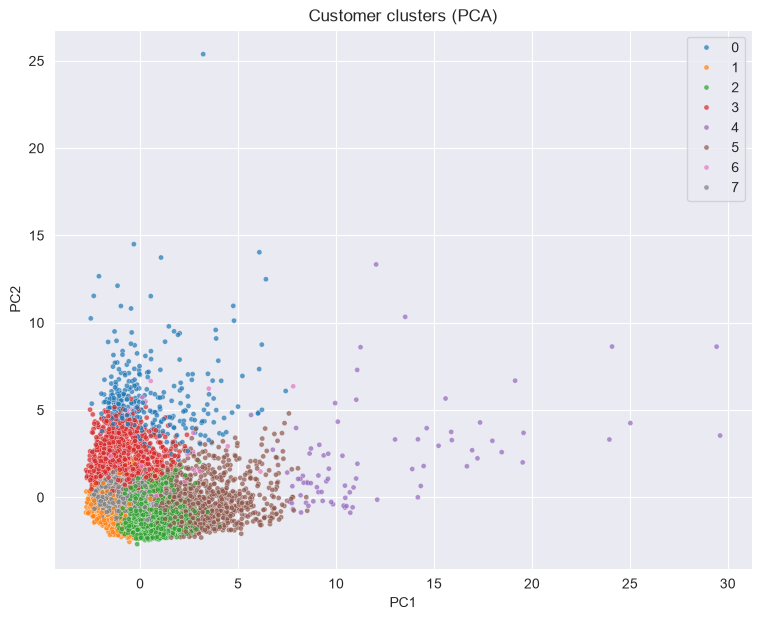

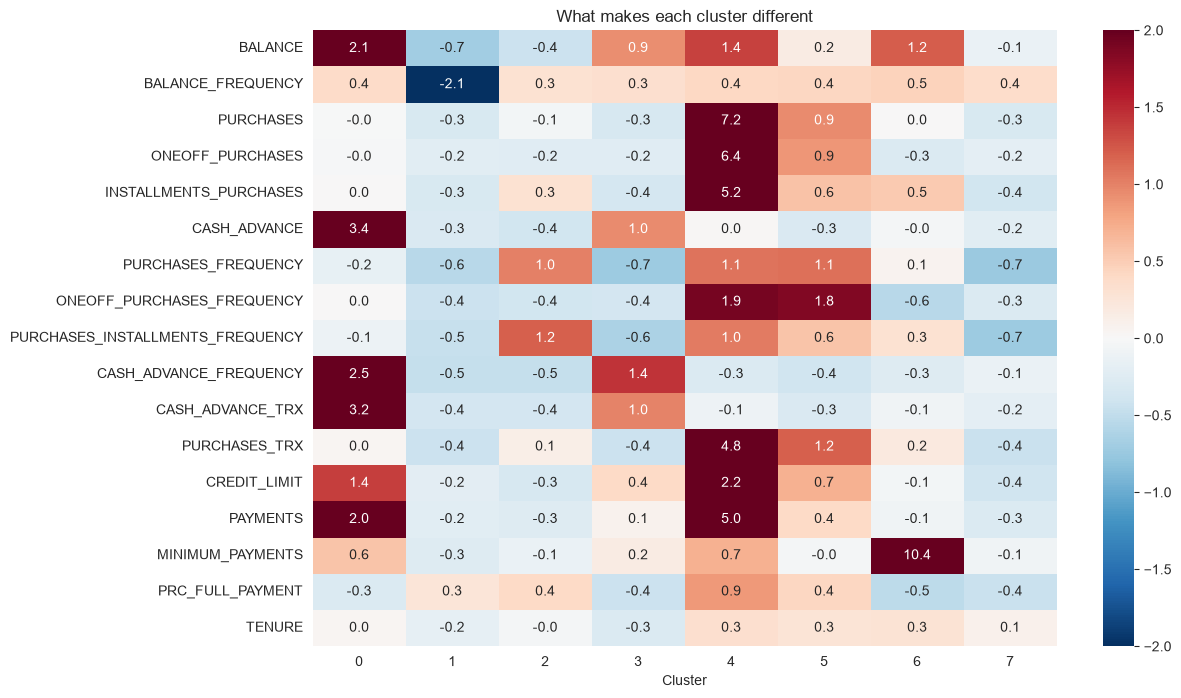

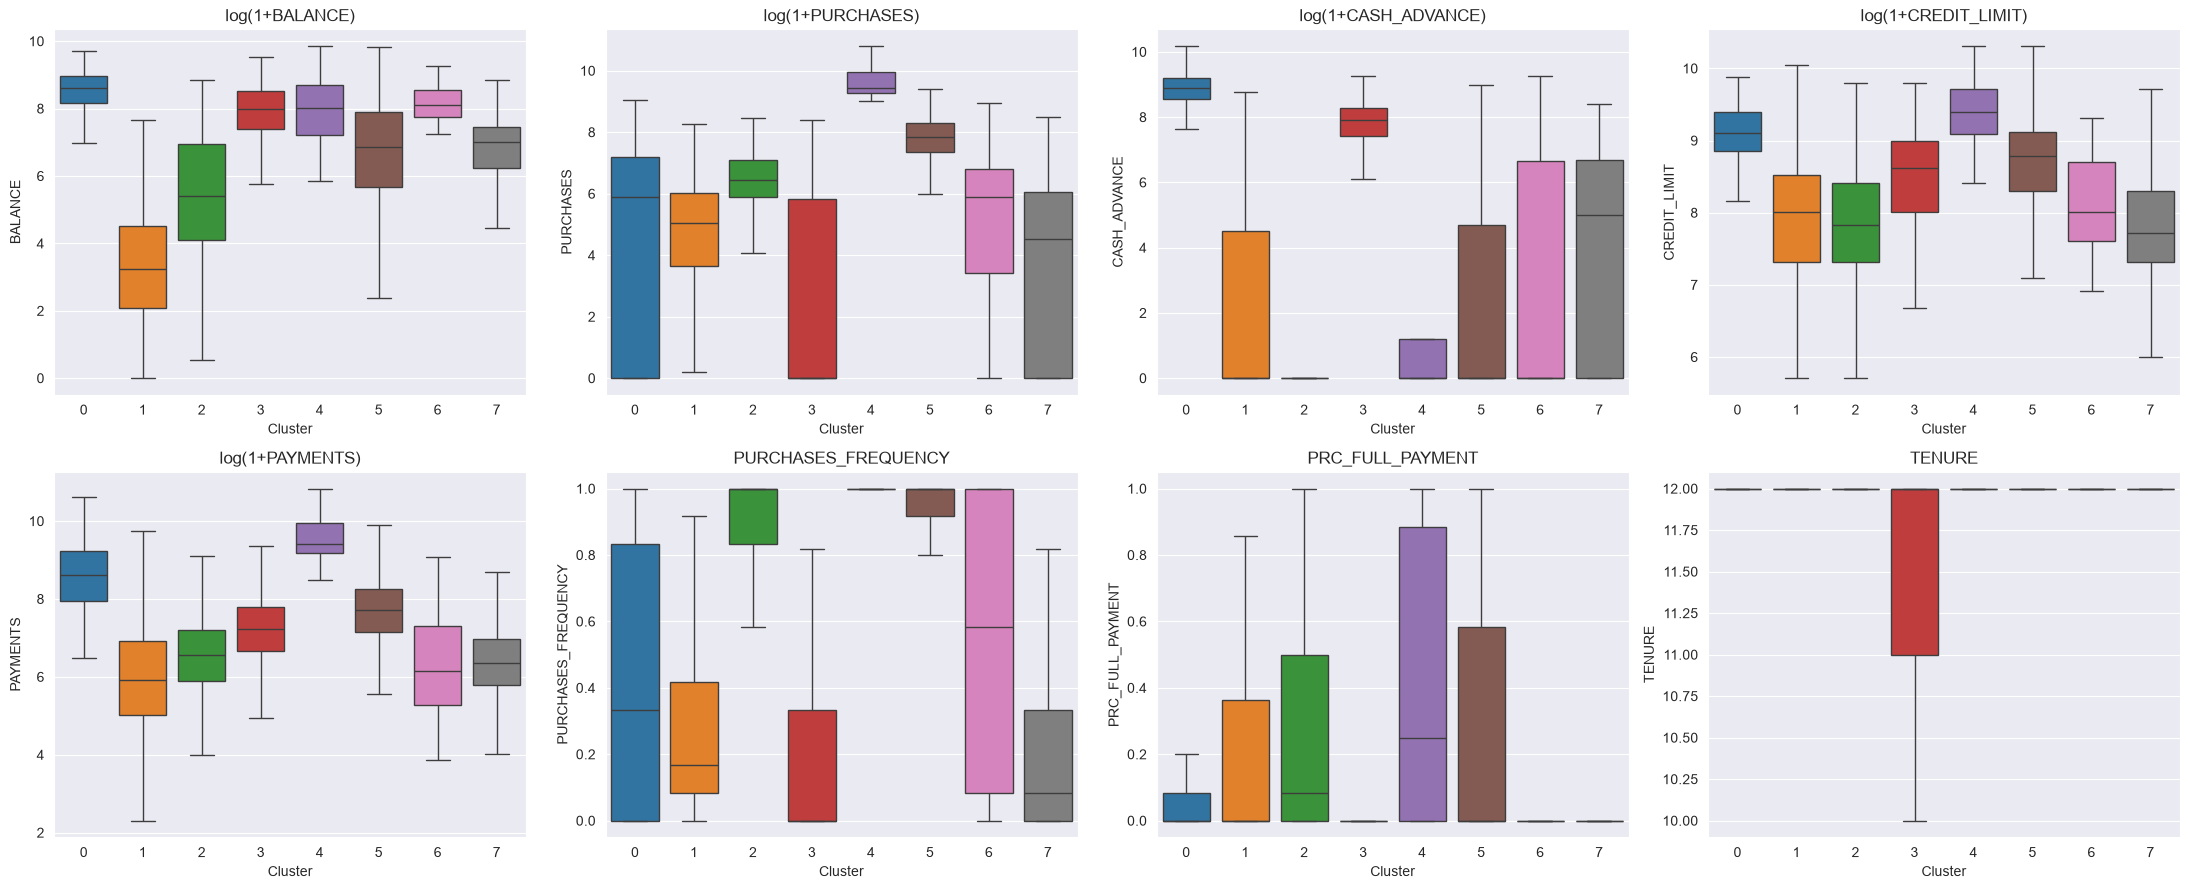

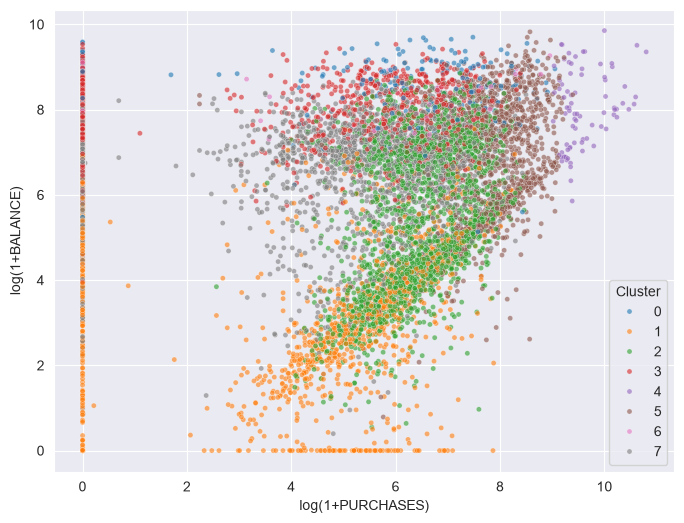

In [36]:
from sklearn.decomposition import PCA

df_clst = df.copy()
df_clst["Cluster"] = y_kmeans
features = df.columns.tolist()
palette = sns.color_palette("tab10", 8)

# 1. Cluster sizes
sizes = df_clst["Cluster"].value_counts().sort_index()
plt.figure(figsize=(9, 4.5))
plt.bar(sizes.index, sizes.values, color=palette)
plt.xlabel("Cluster"); plt.ylabel("Customers"); plt.title("Customers per cluster")
plt.show()

# 2. Clusters in 2-D (PCA)
Z = PCA(n_components=2, random_state=42).fit_transform(df_2)   # df_2 = scaled data
plt.figure(figsize=(9, 7))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=y_kmeans, palette=palette, s=14, alpha=.7)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Customer clusters (PCA)")
plt.show()

# 3. Profile heatmap (std devs from overall mean)
profile = df_clst.groupby("Cluster")[features].mean()
z = (profile - df[features].mean()) / df[features].std()
plt.figure(figsize=(12, 8))
sns.heatmap(z.T, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-2, vmax=2)
plt.title("What makes each cluster different")
plt.show()

# 4. Boxplots of key features per cluster
key = ["BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS", "PURCHASES_FREQUENCY", "PRC_FULL_PAYMENT", "TENURE"]
money = {"BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS"}
fig, axes = plt.subplots(2, 4, figsize=(22, 9))
for ax, col in zip(axes.ravel(), key):
    vals = np.log1p(df_clst[col]) if col in money else df_clst[col]
    sns.boxplot(x=df_clst["Cluster"], y=vals, hue=df_clst["Cluster"], palette=palette,
                legend=False, showfliers=False, ax=ax)
    ax.set_title(f"log(1+{col})" if col in money else col)
plt.tight_layout(); plt.show()

# 5. Purchases vs balance
plt.figure(figsize=(8, 6))
sns.scatterplot(x=np.log1p(df_clst["PURCHASES"]), y=np.log1p(df_clst["BALANCE"]),
                hue=df_clst["Cluster"], palette=palette, s=14, alpha=.6)
plt.xlabel("log(1+PURCHASES)"); plt.ylabel("log(1+BALANCE)")
plt.show()